# Binomial tree option pricer (Corporate Finance, Lecture 7)
This model is used to solve Part 3 questions for Corporate Finance sit in - MSc FIN CBS

Change the numbers in the **INPUT** cell and run the notebook (*Kernel → Restart & Run All*). The notebook then:

1. builds the **stock tree**,
2. values the option by **backward induction** (European or American),
3. shows the **replicating portfolio** at each node: $\Delta$ shares (= $x_2$ in the slides) and $B$ in the risk-free bond (= $x_1$; negative means borrowing),
4. shows the **risk-neutral probability** $q$ at each node,
5. draws the tree and prints a table and the LaTeX working for each node.

**Formulas used at each node** (Lecture 7, "Option Valuation"):

$$\Delta = \frac{C_u - C_d}{S_u - S_d}, \qquad B = \frac{C_d - \Delta S_d}{1+r_f}, \qquad C = \Delta S + B$$

$$q = \frac{(1+r_f)S - S_d}{S_u - S_d}, \qquad C = \frac{q\,C_u + (1-q)\,C_d}{1+r_f}$$

Both routes always give the same price. The notebook computes both and checks that they agree.

**Ways to enter the stock tree:**

| `mode` | When to use it | What you enter |
|---|---|---|
| `"mult"` | The stock goes up/down by a **factor** (e.g. +20% / −10%) | `S0, u, d` |
| `"add"` | The stock goes up/down by a fixed **amount** (e.g. ±10, as in the Lecture 7 example) | `S0, up, down` |
| `"explicit"` | The exam just **gives you the prices** at each node (any tree, recombining or not) | `prices` = list of levels |

For `"explicit"`, each level is listed **top to bottom** (most ups first):
* recombining: level $t$ has $t+1$ numbers, e.g. `[[40],[50,30],[60,40,20]]`
* non-recombining: level $t$ has $2^t$ numbers in the order uu, ud, du, dd, …


In [8]:

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from itertools import product
from IPython.display import display, Math, Markdown
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

def _paths(t):
    return ["".join(p) for p in product("ud", repeat=t)]  

def build_stock_tree(n, mode="mult", S0=None, u=None, d=None, up=None, down=None, prices=None):
    """Return dict path -> stock price, for every path of length 0..n."""
    S = {}
    if mode == "explicit":
        n = len(prices) - 1
        for t, lvl in enumerate(prices):
            if len(lvl) == t + 1:                 
                for p in _paths(t): S[p] = float(lvl[p.count("d")])
            elif len(lvl) == 2 ** t:              
                for i, p in enumerate(_paths(t)): S[p] = float(lvl[i])
            else:
                raise ValueError(f"Level {t} must have {t+1} (recombining) or {2**t} prices, got {len(lvl)}")
        return S, n
    for t in range(n + 1):
        for p in _paths(t):
            k, j = p.count("u"), p.count("d")
            if mode == "mult":  S[p] = S0 * u**k * d**j
            elif mode == "add": S[p] = S0 + k*up - j*down
            else: raise ValueError("mode must be 'mult', 'add' or 'explicit'")
    return S, n

def payoff_fn(kind, K):
    if kind == "call": return lambda S, t=None: max(S - K, 0.0)
    if kind == "put":  return lambda S, t=None: max(K - S, 0.0)
    raise ValueError("kind must be 'call' or 'put' (or pass your own function)")

def price_tree(S, n, rf, payoff, american=False, exercise=None):
    """Backward induction. rf = per-period rate (number, or list with one rate per period)."""
    r = (lambda t: rf[t]) if isinstance(rf, (list, tuple)) else (lambda t: rf)
    exercise = exercise or payoff
    res = {}
    for p in _paths(n):
        res[p] = dict(t=n, S=S[p], V=payoff(S[p], n), delta=np.nan, B=np.nan, q=np.nan,
                      cont=np.nan, ex=np.nan, early=False)
    for t in range(n - 1, -1, -1):
        for p in _paths(t):
            Su, Sd = S[p + "u"], S[p + "d"]
            Vu, Vd = res[p + "u"]["V"], res[p + "d"]["V"]
            R = 1 + r(t)
            if Su == Sd: raise ValueError(f"Node '{p}': S_u = S_d, cannot replicate")
            delta = (Vu - Vd) / (Su - Sd)
            B = (Vd - delta * Sd) / R
            cont = delta * S[p] + B
            q = (R * S[p] - Sd) / (Su - Sd)
            cont_rn = (q * Vu + (1 - q) * Vd) / R
            assert abs(cont - cont_rn) < 1e-9, "replication and risk-neutral price disagree"
            if not (0 < q < 1):
                print(f"WARNING node '{p or 'root'}': q = {q:.4f} outside (0,1), so there is an arbitrage "
                      f"(need S_d < (1+r_f)S < S_u)")
            ex = exercise(S[p], t) if american else np.nan
            V = max(cont, ex) if american else cont
            res[p] = dict(t=t, S=S[p], V=V, delta=delta, B=B, q=q, cont=cont, ex=ex,
                          early=bool(american and ex > cont + 1e-12), R=R, Su=Su, Sd=Sd, Vu=Vu, Vd=Vd)
    return res

def is_recombining(S, n):
    return all(len({S[p] for p in _paths(t) if p.count("u") == k}) == 1
               for t in range(n + 1) for k in range(t + 1))

def table(res, n, recombine=None):
    rows = []
    for t in range(n + 1):
        for p in _paths(t):
            if recombine and p != "u" * p.count("u") + "d" * p.count("d"):
                continue   # show each recombining node once
            r = res[p]
            rows.append({"t": t, "node": p or "0", "S": r["S"], "value": r["V"],
                         "Δ (x2 shares)": r["delta"], "B (x1 bond)": r["B"], "q": r["q"],
                         "exercise now": r["ex"], "early ex?": r["early"]})
    return pd.DataFrame(rows).set_index(["t", "node"])

def draw(res, n, S, label="C", title="", show_q=True):
    rec = is_recombining(S, n)
    fig, ax = plt.subplots(figsize=(3.2 * (n + 1), max(4, 1.6 * (n + 1 if rec else 2 ** n))))
    pos = {}
    for t in range(n + 1):
        for i, p in enumerate(_paths(t)):
            y = (t - 2 * p.count("d")) if rec else ((2 ** n) * (1 - (2 * i + 1) / 2 ** t))
            pos[p] = (t, y)
    drawn = set()
    for t in range(n):
        for p in _paths(t):
            for c in "ud":
                (x0, y0), (x1, y1) = pos[p], pos[p + c]
                ax.plot([x0, x1], [y0, y1], color="#9aa5b1", lw=1.2, zorder=1)
                if show_q and not np.isnan(res[p]["q"]) and (rec is False or (pos[p], c) not in drawn):
                    qq = res[p]["q"] if c == "u" else 1 - res[p]["q"]
                    ax.text((x0 + x1) / 2, (y0 + y1) / 2 + (0.12 if c == "u" else -0.12) * (1 if rec else 2 ** (n - t - 1)),
                            f"{'q' if c=='u' else '1-q'}={qq:.3f}", fontsize=7.5, color="#52606d",
                            ha="center", va="center")
                    drawn.add((pos[p], c))
    seen = set()
    for p, (x, y) in pos.items():
        if (x, y) in seen: continue
        seen.add((x, y))
        r = res[p]
        lines = [f"S = {r['S']:.3f}", f"{label} = {r['V']:.3f}"]
        if r["t"] < n:
            lines += [f"Δ = {r['delta']:.3f}", f"B = {r['B']:.3f}"]
        face = "#ffe0e0" if r["early"] else ("#e3f2fd" if r["t"] < n else "#f1f8e9")
        ax.text(x, y, "\n".join(lines), ha="center", va="center", fontsize=9, family="monospace",
                bbox=dict(boxstyle="round,pad=0.4", fc=face, ec="#3e4c59"), zorder=3)
    ax.set_xticks(range(n + 1)); ax.set_xticklabels([f"t = {t}" for t in range(n + 1)])
    ax.set_yticks([]); ax.set_xlim(-0.5, n + 0.5)
    for s in ["left", "right", "top"]: ax.spines[s].set_visible(False)
    ax.set_title(title + ("   (red = exercise early)" if any(v["early"] for v in res.values()) else ""))
    plt.tight_layout(); plt.show()

def node_math(res, p="", label="C"):
    """LaTeX working for one node: general formula, then with numbers."""
    r = res[p]; name = p or "0"
    if r["t"] == len(max(res, key=len)):
        display(Math(rf"\text{{Node {name} (maturity): }} {label} = \text{{payoff}}(S={r['S']:.3f}) = {r['V']:.3f}")); return
    f = lambda x: f"{x:.3f}" if x >= 0 else f"({x:.3f})"
    display(Markdown(f"**Node `{name}`** (t = {r['t']}, S = {r['S']:.3f})"))
    display(Math(rf"\Delta = \frac{{{label}_u-{label}_d}}{{S_u-S_d}} = \frac{{{f(r['Vu'])}-{f(r['Vd'])}}}{{{f(r['Su'])}-{f(r['Sd'])}}} = {r['delta']:.3f}"))
    display(Math(rf"B = \frac{{{label}_d-\Delta S_d}}{{1+r_f}} = \frac{{{f(r['Vd'])}-{r['delta']:.3f}\cdot {f(r['Sd'])}}}{{{r['R']:.4g}}} = {r['B']:.3f}"))
    display(Math(rf"{label} = \Delta S + B = {r['delta']:.3f}\cdot{f(r['S'])} + {f(r['B'])} = {r['cont']:.3f}"))
    display(Math(rf"q = \frac{{(1+r_f)S-S_d}}{{S_u-S_d}} = \frac{{{r['R']:.4g}\cdot{f(r['S'])}-{f(r['Sd'])}}}{{{f(r['Su'])}-{f(r['Sd'])}}} = {r['q']:.3f}"
                 rf"\;\Rightarrow\; {label} = \frac{{{r['q']:.3f}\cdot{f(r['Vu'])} + {1-r['q']:.3f}\cdot{f(r['Vd'])}}}{{{r['R']:.4g}}} = {r['cont']:.3f}"))
    if not np.isnan(r["ex"]):
        display(Math(rf"\text{{American: }} {label} = \max(\text{{continue}},\ \text{{exercise}}) = \max({r['cont']:.3f},\ {r['ex']:.3f}) = {r['V']:.3f}"
                     + (r"\ \text{(exercise early)}" if r["early"] else "")))

def run(inp):
    S, n = build_stock_tree(inp.get("n"), inp["mode"], inp.get("S0"), inp.get("u"), inp.get("d"),
                            inp.get("up"), inp.get("down"), inp.get("prices"))
    pay = inp.get("payoff") or payoff_fn(inp["kind"], inp["K"])
    res = price_tree(S, n, inp["rf"], pay, inp.get("american", False), inp.get("exercise"))
    rec = is_recombining(S, n)
    label = inp.get("label", "C" if inp.get("kind") == "call" else "P" if inp.get("kind") == "put" else "V")
    style = "American" if inp.get("american") else "European"
    display(Markdown(f"### {inp.get('title','')}\n**{style} {inp.get("kind") or "custom payoff"}**, "
                     f"{n} periods, {'recombining' if rec else 'non-recombining'} tree. "
                     f"**Price today: {label}₀ = {res['']['V']:.3f}**"))
    draw(res, n, S, label, inp.get("title", ""))
    display(table(res, n, rec))
    if inp.get("show_math", True):
        nodes = [p for t in range(n) for p in _paths(t)
                 if not rec or p == "u" * p.count("u") + "d" * p.count("d")]
        for p in reversed(nodes): node_math(res, p, label)
    return res, S, n


---
## INPUT: edit this cell
The example is the **Lecture 7 two-period example** (slides 53–55): $S_0=40$, ±10 per period, European call with $K=50$, $r_f=6\%$.
Expected result: the up-node at $t=1$ is worth 6.132 (slide 54) and the price today is 3.587.

### Lecture 7 two-period example
**European call**, 4 periods, recombining tree. **Price today: C₀ = 7.325**

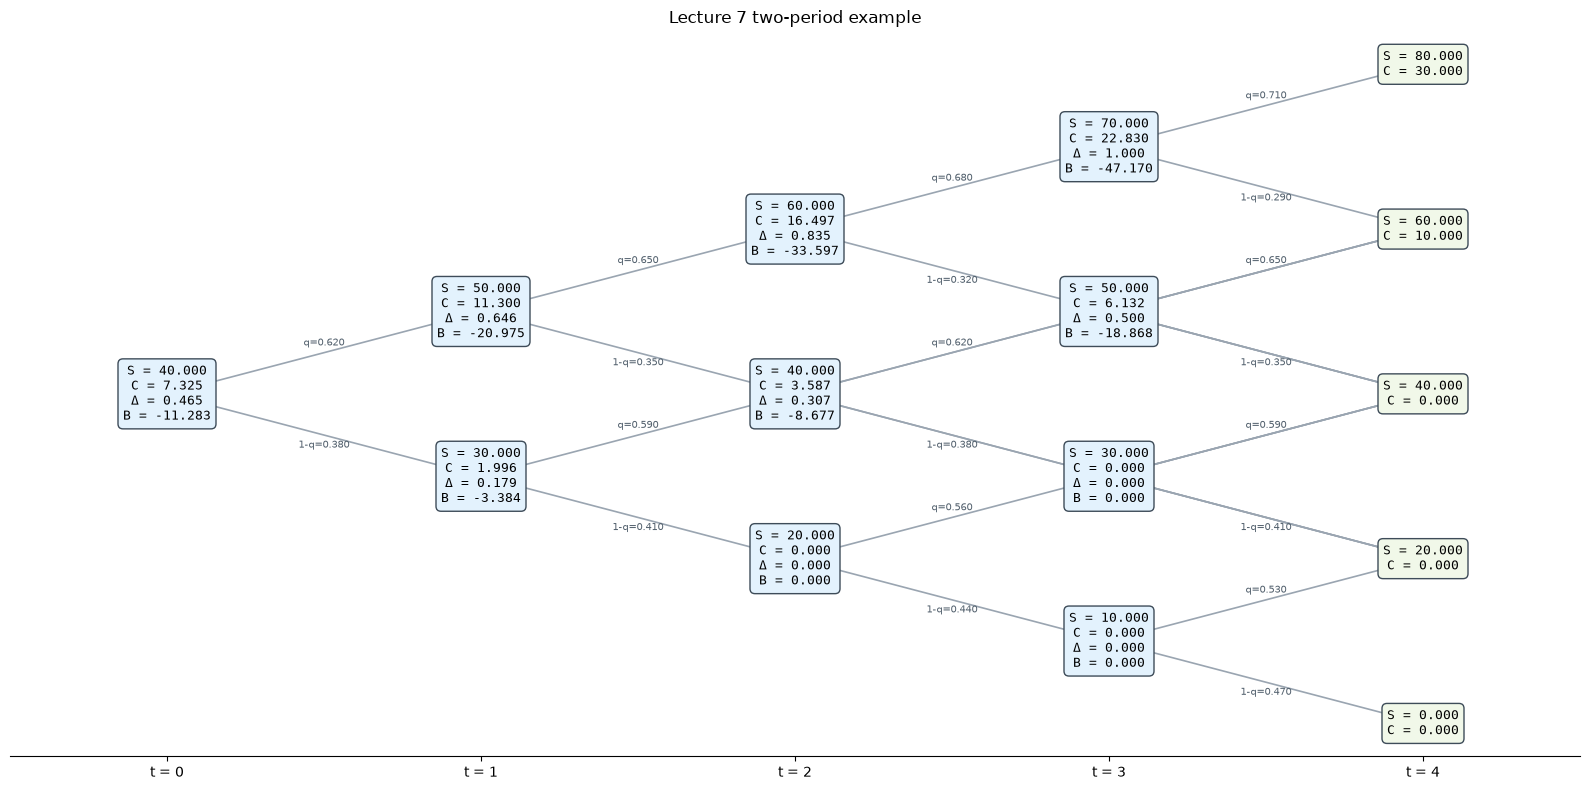

S  value  Δ (x2 shares)  B (x1 bond)     q  exercise now  early ex?
t node                                                                      
0 0     40  7.325          0.465      -11.283 0.620           NaN      False
1 u     50 11.300          0.646      -20.975 0.650           NaN      False
  d     30  1.996          0.179       -3.384 0.590           NaN      False
2 uu    60 16.497          0.835      -33.597 0.680           NaN      False
  ud    40  3.587          0.307       -8.677 0.620           NaN      False
  dd    20  0.000          0.000        0.000 0.560           NaN      False
3 uuu   70 22.830          1.000      -47.170 0.710           NaN      False
  uud   50  6.132          0.500      -18.868 0.650           NaN      False
  udd   30  0.000          0.000        0.000 0.590           NaN      False
  ddd   10  0.000          0.000        0.000 0.530           NaN      False
4 uuuu  80 30.000            NaN          NaN   NaN           NaN      False
  uuud  60 10.000            NaN          NaN   NaN           NaN      False
  uudd  40  0.000            NaN          NaN   NaN           NaN      False
  uddd  20  0.000            NaN          NaN   NaN           NaN      False
  dddd   0  0.000            NaN          NaN   NaN           NaN      False

**Node `ddd`** (t = 3, S = 10.000)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

... (41 outputs left out)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [ ]:
inp = dict(
    title    = "Lecture 7 two-period example",
    mode     = "add",        # "mult" (u, d factors) | "add" (up/down amounts) | "explicit" (prices list)
    n        = 4,            # number of periods (ignored for "explicit")
    S0       = 40,
    up       = 10,  down = 10,          # for mode="add"
    u        = None, d   = None,        # for mode="mult", e.g. u=1.2, d=0.9
    prices   = None,                    # for mode="explicit"
    rf       = 0.06,         # per-period risk-free rate (or list, one per period)
    kind     = "call",       # "call" or "put"
    K        = 50,
    american = False,        # True: check early exercise at every node
    show_math = True,        # print LaTeX working for every node
)
res, S, n = run(inp)


---
## More examples (copy one into the INPUT cell or run as is)

### A. Multiplicative tree, American put
$S_0=100$, $u=1.2$, $d=0.9$, $r_f=5\%$ per period, 3 periods, $K=105$. Red boxes mark nodes where early exercise is optimal. There the node value is the exercise value; the Δ and B shown replicate the *continuation* value.

### American put, u=1.2, d=0.9
**American put**, 3 periods, recombining tree. **Price today: P₀ = 7.985**

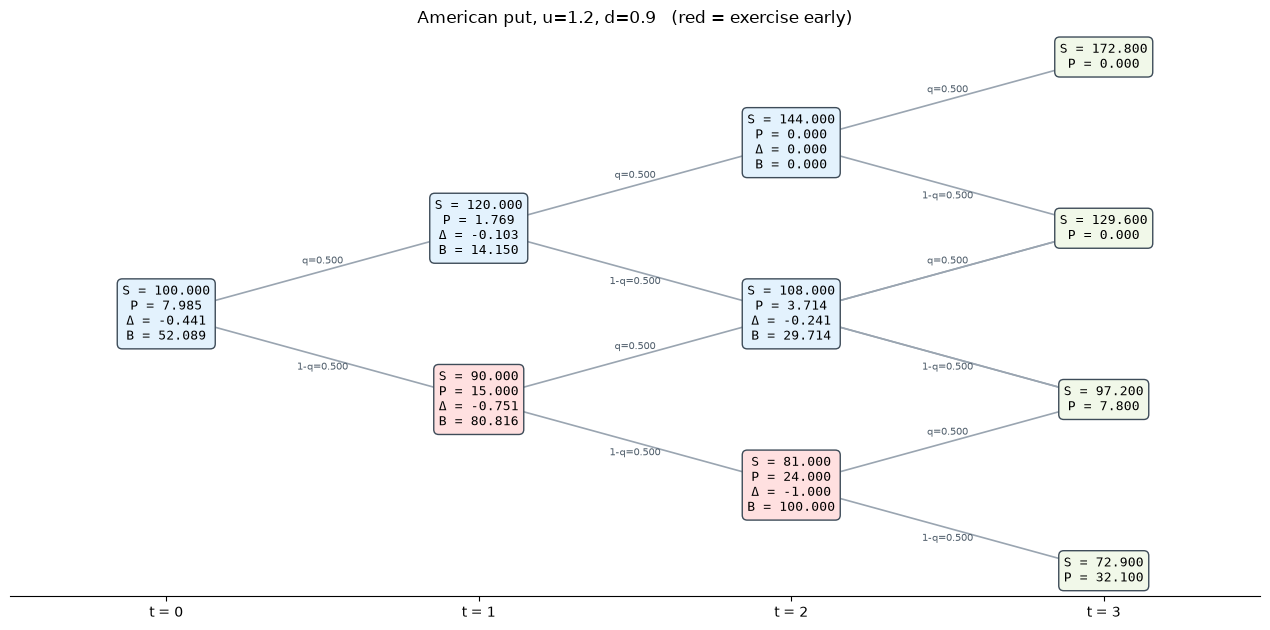

S  value  Δ (x2 shares)  B (x1 bond)     q  exercise now  \
t node                                                                  
0 0    100.000  7.985         -0.441       52.089 0.500         5.000   
1 u    120.000  1.769         -0.103       14.150 0.500         0.000   
  d     90.000 15.000         -0.751       80.816 0.500        15.000   
2 uu   144.000  0.000          0.000        0.000 0.500         0.000   
  ud   108.000  3.714         -0.241       29.714 0.500         0.000   
  dd    81.000 24.000         -1.000      100.000 0.500        24.000   
3 uuu  172.800  0.000            NaN          NaN   NaN           NaN   
  uud  129.600  0.000            NaN          NaN   NaN           NaN   
  udd   97.200  7.800            NaN          NaN   NaN           NaN   
  ddd   72.900 32.100            NaN          NaN   NaN           NaN   

        early ex?  
t node             
0 0         False  
1 u         False  
  d          True  
2 uu        False  
  ud        False  
  dd         True  
3 uuu       False  
  uud       False  
  udd       False  
  ddd       False

### European put (same inputs)
**European put**, 3 periods, recombining tree. **Price today: P₀ = 5.993**

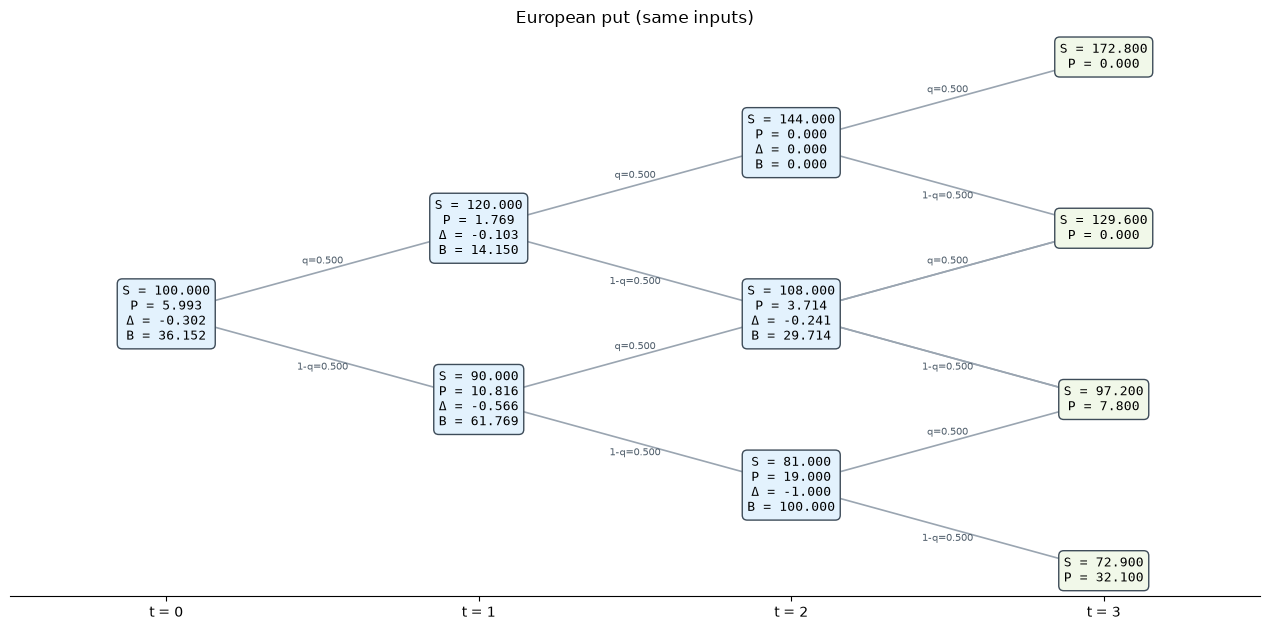

S  value  Δ (x2 shares)  B (x1 bond)     q  exercise now  \
t node                                                                  
0 0    100.000  5.993         -0.302       36.152 0.500           NaN   
1 u    120.000  1.769         -0.103       14.150 0.500           NaN   
  d     90.000 10.816         -0.566       61.769 0.500           NaN   
2 uu   144.000  0.000          0.000        0.000 0.500           NaN   
  ud   108.000  3.714         -0.241       29.714 0.500           NaN   
  dd    81.000 19.000         -1.000      100.000 0.500           NaN   
3 uuu  172.800  0.000            NaN          NaN   NaN           NaN   
  uud  129.600  0.000            NaN          NaN   NaN           NaN   
  udd   97.200  7.800            NaN          NaN   NaN           NaN   
  ddd   72.900 32.100            NaN          NaN   NaN           NaN   

        early ex?  
t node             
0 0         False  
1 u         False  
  d         False  
2 uu        False  
  ud        False  
  dd        False  
3 uuu       False  
  uud       False  
  udd       False  
  ddd       False

Early-exercise premium = 1.992


In [ ]:
res_A, S_A, n_A = run(dict(title="American put, u=1.2, d=0.9", mode="mult", n=3, S0=100, u=1.2, d=0.9,
                           rf=0.05, kind="put", K=105, american=True, show_math=False))
res_Ae, *_ = run(dict(title="European put (same inputs)", mode="mult", n=3, S0=100, u=1.2, d=0.9,
                      rf=0.05, kind="put", K=105, american=False, show_math=False))
print(f"Early-exercise premium = {res_A['']['V'] - res_Ae['']['V']:.3f}")


### B. Prices given directly in the exam (explicit, non-recombining)
Level $t$ has $2^t$ prices in the order uu, ud, du, dd.

### Explicit non-recombining tree
**European call**, 2 periods, non-recombining tree. **Price today: C₀ = 10.700**

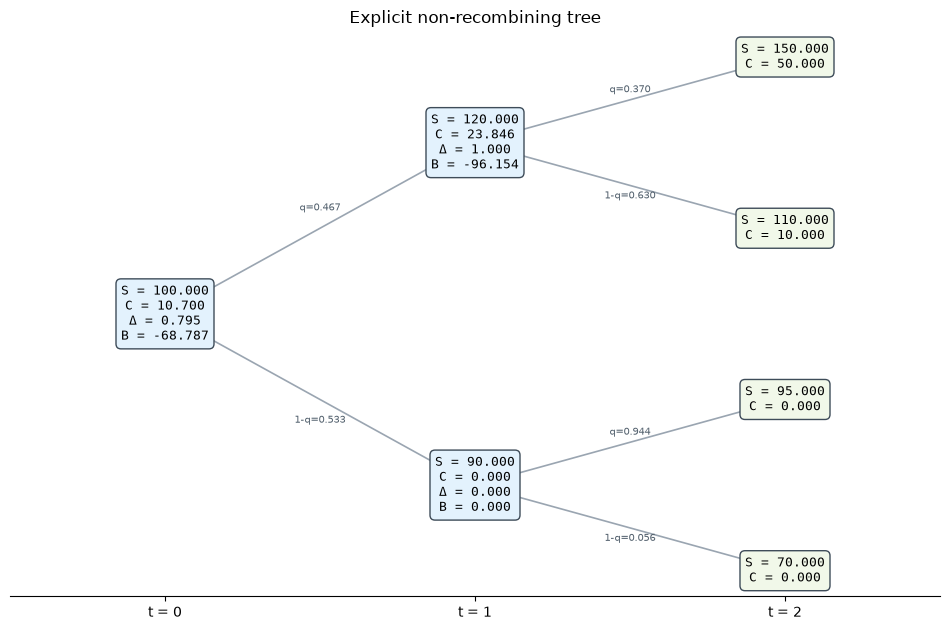

S  value  Δ (x2 shares)  B (x1 bond)     q  exercise now  \
t node                                                                  
0 0    100.000 10.700          0.795      -68.787 0.467           NaN   
1 u    120.000 23.846          1.000      -96.154 0.370           NaN   
  d     90.000  0.000          0.000        0.000 0.944           NaN   
2 uu   150.000 50.000            NaN          NaN   NaN           NaN   
  ud   110.000 10.000            NaN          NaN   NaN           NaN   
  du    95.000  0.000            NaN          NaN   NaN           NaN   
  dd    70.000  0.000            NaN          NaN   NaN           NaN   

        early ex?  
t node             
0 0         False  
1 u         False  
  d         False  
2 uu        False  
  ud        False  
  du        False  
  dd        False

**Node `d`** (t = 1, S = 90.000)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

... (6 outputs left out)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [11]:
res_B, *_ = run(dict(title="Explicit non-recombining tree", mode="explicit",
                     prices=[[100], [120, 90], [150, 110, 95, 70]],
                     rf=0.04, kind="call", K=100, show_math=True))


### C. Real option / custom payoff
Any payoff can be priced. Pass `payoff=lambda S, t: ...` (and for American options `exercise=lambda S, t: ...`).
Example: the underlying is a **project value** $V$; you can **abandon** it at any time for a salvage value of 80.
The option is then an American put on $V$ with $K=80$. To value the project *including* the option, use payoff $\max(V,80)$.

### Project with abandonment option (value incl. option)
**American custom payoff**, 3 periods, recombining tree. **Price today: V₀ = 102.867**

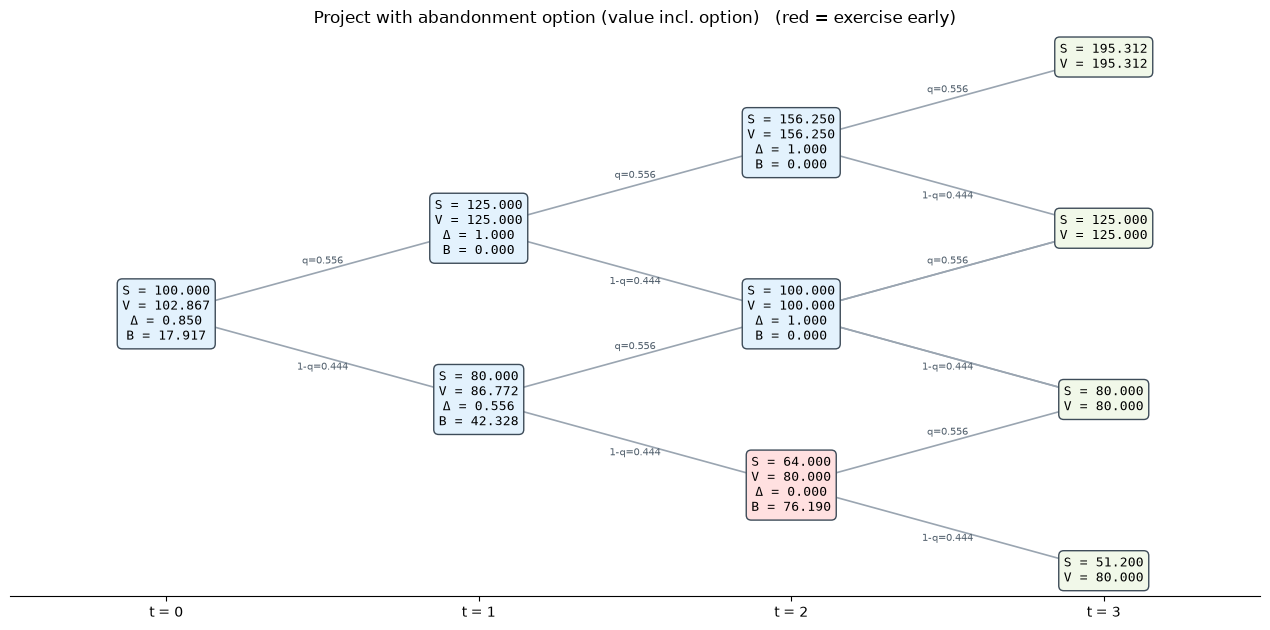

S   value  Δ (x2 shares)  B (x1 bond)     q  exercise now  \
t node                                                                   
0 0    100.000 102.867          0.850       17.917 0.556        80.000   
1 u    125.000 125.000          1.000        0.000 0.556        80.000   
  d     80.000  86.772          0.556       42.328 0.556        80.000   
2 uu   156.250 156.250          1.000        0.000 0.556        80.000   
  ud   100.000 100.000          1.000        0.000 0.556        80.000   
  dd    64.000  80.000          0.000       76.190 0.556        80.000   
3 uuu  195.312 195.312            NaN          NaN   NaN           NaN   
  uud  125.000 125.000            NaN          NaN   NaN           NaN   
  udd   80.000  80.000            NaN          NaN   NaN           NaN   
  ddd   51.200  80.000            NaN          NaN   NaN           NaN   

        early ex?  
t node             
0 0         False  
1 u         False  
  d         False  
2 uu        False  
  ud        False  
  dd         True  
3 uuu       False  
  uud       False  
  udd       False  
  ddd       False

Value of abandonment option = 2.867


In [12]:
salvage = 80
res_C, *_ = run(dict(title="Project with abandonment option (value incl. option)", mode="mult", n=3,
                     S0=100, u=1.25, d=0.8, rf=0.05, kind=None, label="V",
                     payoff=lambda S, t: max(S, salvage), american=True,
                     exercise=lambda S, t: salvage, show_math=False))
print(f"Value of abandonment option = {res_C['']['V'] - 100:.3f}")


---
## Sanity checks
* **Lecture 7 numbers**: node *u* = 6.132, root = 3.585.
* **Put–call parity** (European, constant $r_f$): $C - P = S_0 - K/(1+r_f)^n$.
* **CRR closed form** (multiplicative tree): $C = \frac{1}{(1+r_f)^n}\sum_{k=0}^{n}\binom{n}{k}q^k(1-q)^{n-k}\max(S_0u^kd^{n-k}-K,0)$.
* American call on a non-dividend stock = European call. An American put is worth at least the European put.

In [13]:
from math import comb
# 1) Lecture 7
r1, *_ = (price_tree(*build_stock_tree(2, "add", 40, up=10, down=10), 0.06, payoff_fn("call", 50)),)
print("Lecture 7: node u =", round(r1["u"]["V"], 3), "| root =", round(r1[""]["V"], 3))

S0, u, d, rf, K, n = 100, 1.2, 0.9, 0.05, 105, 3
St, _ = build_stock_tree(n, "mult", S0, u, d)
C = price_tree(St, n, rf, payoff_fn("call", K))[""]["V"]
P = price_tree(St, n, rf, payoff_fn("put", K))[""]["V"]
print(f"Parity: C - P = {C-P:.6f}   vs   S0 - K/(1+rf)^n = {S0 - K/(1+rf)**n:.6f}")
q = ((1+rf) - d) / (u - d)
C_crr = sum(comb(n,k) * q**k * (1-q)**(n-k) * max(S0*u**k*d**(n-k) - K, 0) for k in range(n+1)) / (1+rf)**n
print(f"CRR closed form C = {C_crr:.6f}   vs tree C = {C:.6f}")
Cam = price_tree(St, n, rf, payoff_fn("call", K), american=True)[""]["V"]
print(f"American call = {Cam:.6f} (should equal European {C:.6f})")


Lecture 7: node u = 6.132 | root = 3.587
Parity: C - P = 9.297052   vs   S0 - K/(1+rf)^n = 9.297052
CRR closed form C = 15.289925   vs tree C = 15.289925
American call = 15.289925 (should equal European 15.289925)
